# Ecommerce Return Classification

### Defining Business Problem:
> Business is getting too many returns and we have data of Orders from cart amount to return risk or return success

### Identifying Target Variable
> return_risk_label

#### Why:
> Need to minimize risk for returns on Orders.

### Basic Explaining Of Business pronlem
> An Ecommerce Business company  wants to predict which orders are likely to be returned, So it can be Identify high risk order and reduce Product Returns.

### How ML can address the problem?
> In this problem we can use Classification Models that can help us to identify either received order has high return risk or not.

# Data Understanding &amp; EDA

### Dataset structure and data types

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("../raw_data/ecommerce_return_classification.csv")

In [3]:
df.head()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,172.17,0.233,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,213.55,0.235,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,152.68,0.133,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2993 entries, 0 to 2992
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cart_value_usd         2993 non-null   float64
 1   past_return_rate       2993 non-null   float64
 2   size_bracketing_flag   2993 non-null   int64  
 3   delivery_days_taken    2993 non-null   int64  
 4   discount_pct_applied   2993 non-null   int64  
 5   product_category       2993 non-null   str    
 6   fit_review_sentiment   2993 non-null   str    
 7   newsletter_subscriber  2993 non-null   int64  
 8   browser_used           2993 non-null   str    
 9   checkout_device        2993 non-null   str    
 10  packaging_color        2993 non-null   str    
 11  loyalty_card_color     2993 non-null   str    
 12  return_risk_label      2993 non-null   int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 481.6 KB


### Descriptive statistics

In [5]:
df.describe()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,newsletter_subscriber,return_risk_label
count,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000
mean,239.630274,0.284024,0.354160,5.974273,23.879051,0.503508,0.645506
std,121.454170,0.159998,0.478338,3.188330,17.263143,0.500071,0.478440
min,0.000000,0.005000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,135.370000,0.157000,0.000000,3.000000,10.000000,0.000000,0.000000
50%,238.690000,0.265000,0.000000,6.000000,20.000000,1.000000,1.000000
75%,343.680000,0.386000,1.000000,9.000000,40.000000,1.000000,1.000000
max,449.860000,0.884000,1.000000,11.000000,50.000000,1.000000,1.000000


### Missing values and duplicates

In [6]:
df.isnull().sum()

cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

### Helping and Reuseable Code

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
all_num_cols = df.describe().columns
all_cat_cols = df.describe(include="O").columns

def showBoxPlot(data, col):
    plt.title(f"Box plot for Checking Outliers for: {col}")
    sns.boxplot(x=data[col])
    plt.xlabel(col)
    plt.show()

/var/folders/41/49dnj5213l1f6btjl3b5rdlh0000gn/T/ipykernel_4238/2311315400.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  all_cat_cols = df.describe(include="O").columns


### Outlier analysis

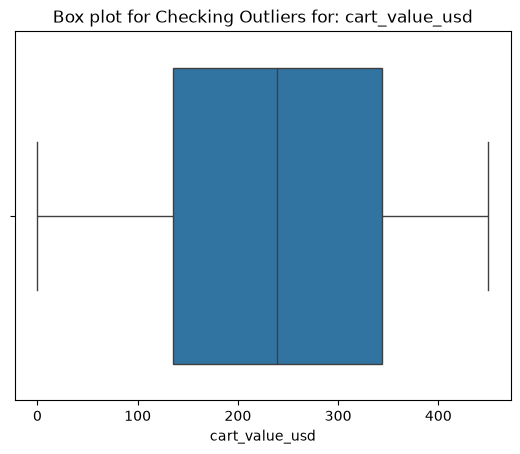

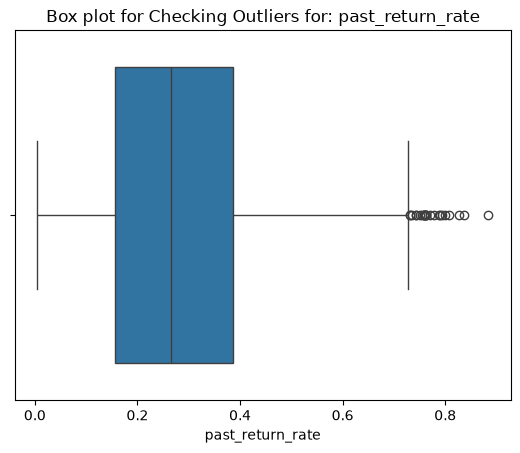

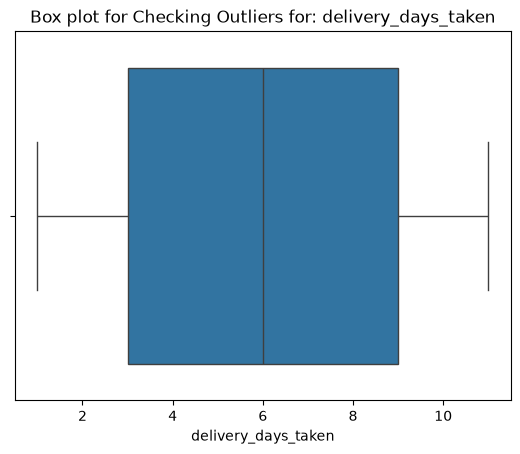

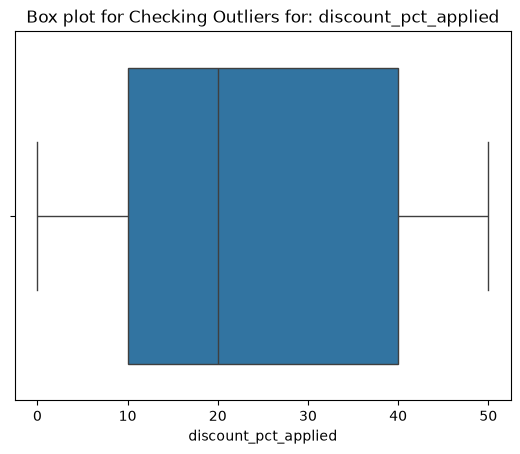

In [10]:
for col in all_num_cols.drop(["return_risk_label", "newsletter_subscriber", "size_bracketing_flag"]):
    showBoxPlot(df, col)

We Can Clearly see Outliers in Past Return Rate So need to remove Outlier in data

In [11]:
q1 = df["past_return_rate"].quantile(0.25)
q3 = df["past_return_rate"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

print("Lower Bound: ", lower_bound)
print("Upper Bound: ", upper_bound)

lower_bound = lower_bound if lower_bound >= 0  else 0

print(lower_bound)

Lower Bound:  -0.18650000000000003
Upper Bound:  0.7295
0


In [12]:
df = df[(df["past_return_rate"] > lower_bound) & (df["past_return_rate"] < upper_bound)]

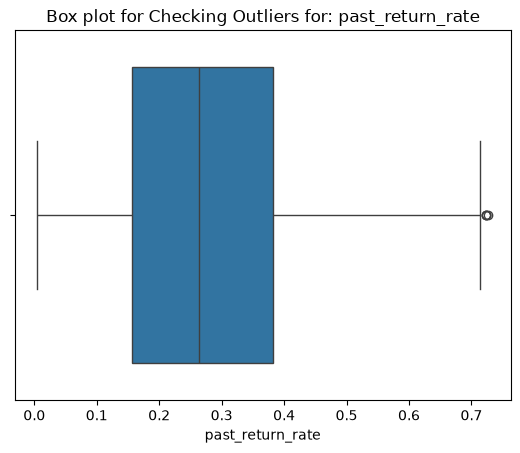

In [13]:
showBoxPlot(df, "past_return_rate")

### Relevant visualizations

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


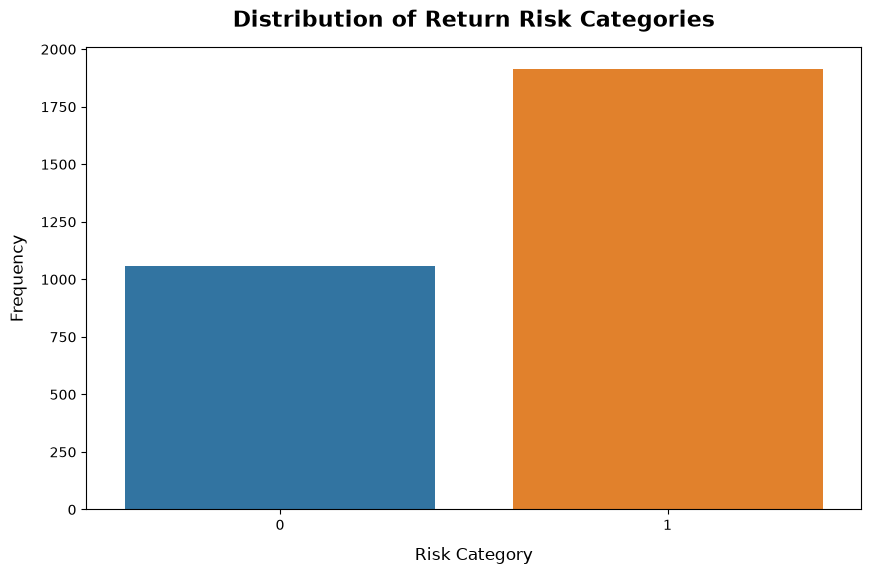

In [14]:
plt.figure(figsize=(10, 6))

counts = df["return_risk_label"].value_counts()

ax = sns.barplot(
    x=counts.index, 
    y=counts.values, 
    hue=counts.index, 
    legend=False
)

plt.title("Distribution of Return Risk Categories", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Risk Category", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Frequency", fontsize=12, fontweight="medium", labelpad=10)

plt.show()

In [15]:
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

<Axes: xlabel='cart_value_usd', ylabel='past_return_rate'>

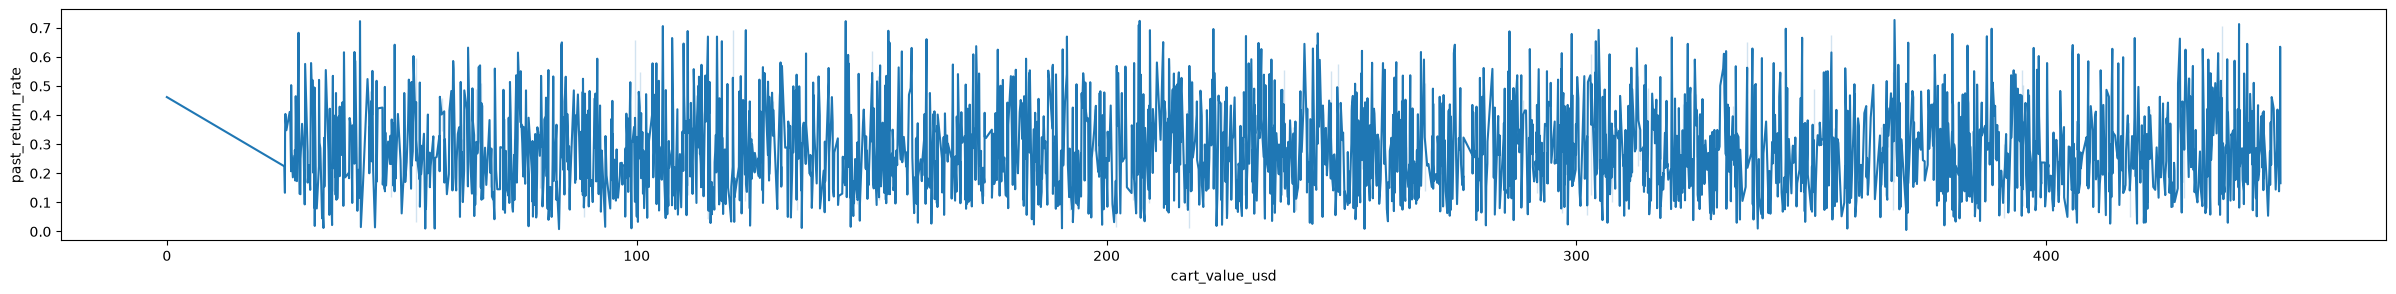

In [16]:
plt.figure(figsize=(30, 3))
sns.lineplot( x="cart_value_usd", y="past_return_rate", data=df)

findfont: Failed to find font weight medium for Arial, now using 400.


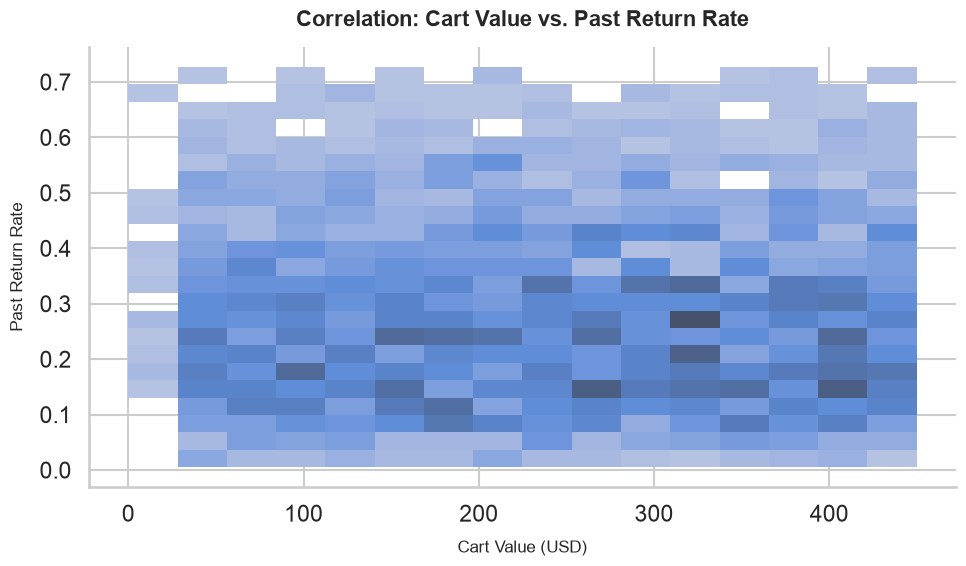

In [17]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid", context="talk")

sns.histplot(
    x="cart_value_usd", 
    y="past_return_rate", 
    data=df,
)

plt.title("Correlation: Cart Value vs. Past Return Rate", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Cart Value (USD)", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Past Return Rate", fontsize=12, fontweight="medium", labelpad=10)

sns.despine()
plt.tight_layout()
plt.show()

<Axes: xlabel='delivery_days_taken', ylabel='past_return_rate'>

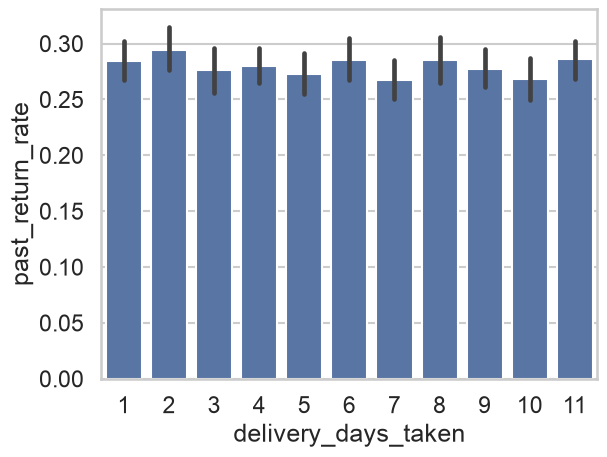

In [18]:
sns.barplot(
    data=df,
    x="delivery_days_taken",
    y="past_return_rate"
)

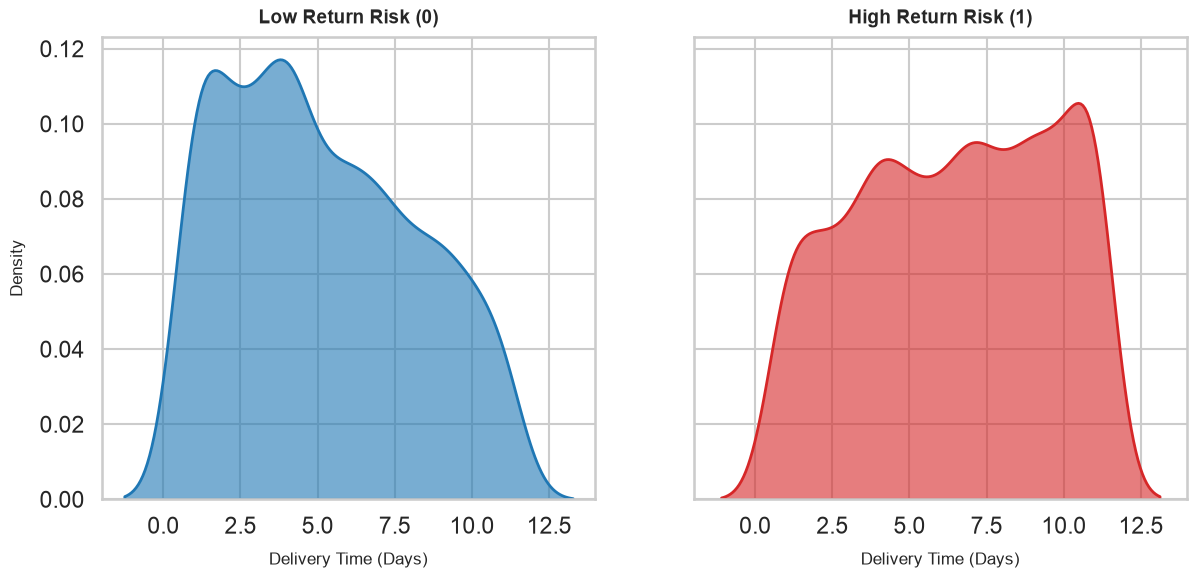

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), sharex=True, sharey=True)

sns.kdeplot(
    data=df[df["return_risk_label"] == 0],
    x="delivery_days_taken",
    fill=True,
    alpha=0.6,
    color="#1f77b4", # Blue implies normal/safe
    linewidth=2,
    ax=axes[0]
)
axes[0].set_title("Low Return Risk (0)", fontsize=14, fontweight="bold", pad=10)
axes[0].set_xlabel("Delivery Time (Days)", fontsize=12, fontweight="medium", labelpad=10)
axes[0].set_ylabel("Density", fontsize=12, fontweight="medium", labelpad=10)

sns.kdeplot(
    data=df[df["return_risk_label"] == 1],
    x="delivery_days_taken",
    fill=True,
    alpha=0.6,
    color="#d62728", # Red implies risk/action
    linewidth=2,
    ax=axes[1]
)
axes[1].set_title("High Return Risk (1)", fontsize=14, fontweight="bold", pad=10)
axes[1].set_xlabel("Delivery Time (Days)", fontsize=12, fontweight="medium", labelpad=10)

axes[1].set_ylabel("") 

plt.show()

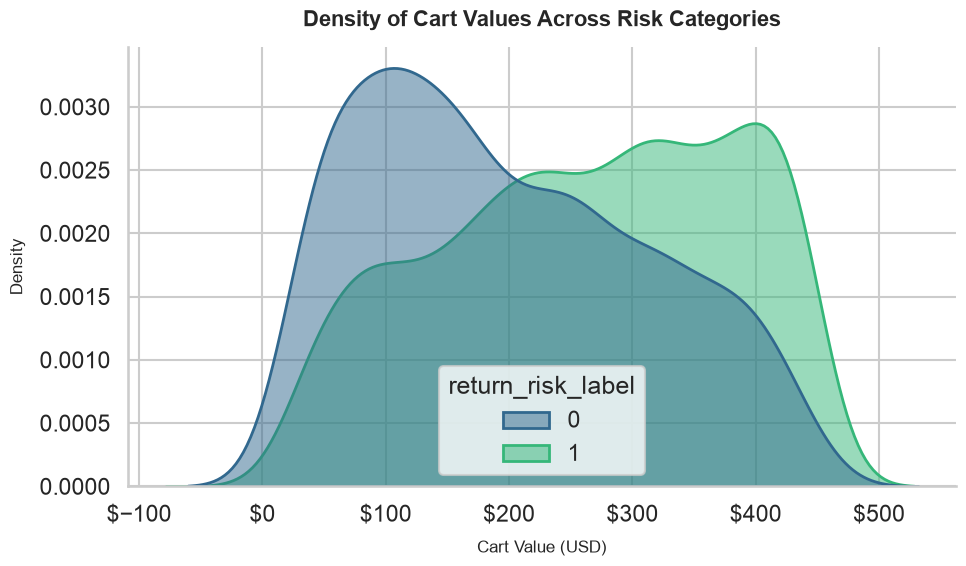

In [20]:
plt.figure(figsize=(10, 6))

ax2 = sns.kdeplot(
    data=df,
    x="cart_value_usd",
    hue="return_risk_label",
    fill=True,
    alpha=0.5,
    palette="viridis",
    linewidth=2,
    common_norm=False # Ensures each density curve integrates to 1 independently
)

plt.title("Density of Cart Values Across Risk Categories", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Cart Value (USD)", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Density", fontsize=12, fontweight="medium", labelpad=10)

ax2.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))

sns.despine()
plt.tight_layout()
plt.show()


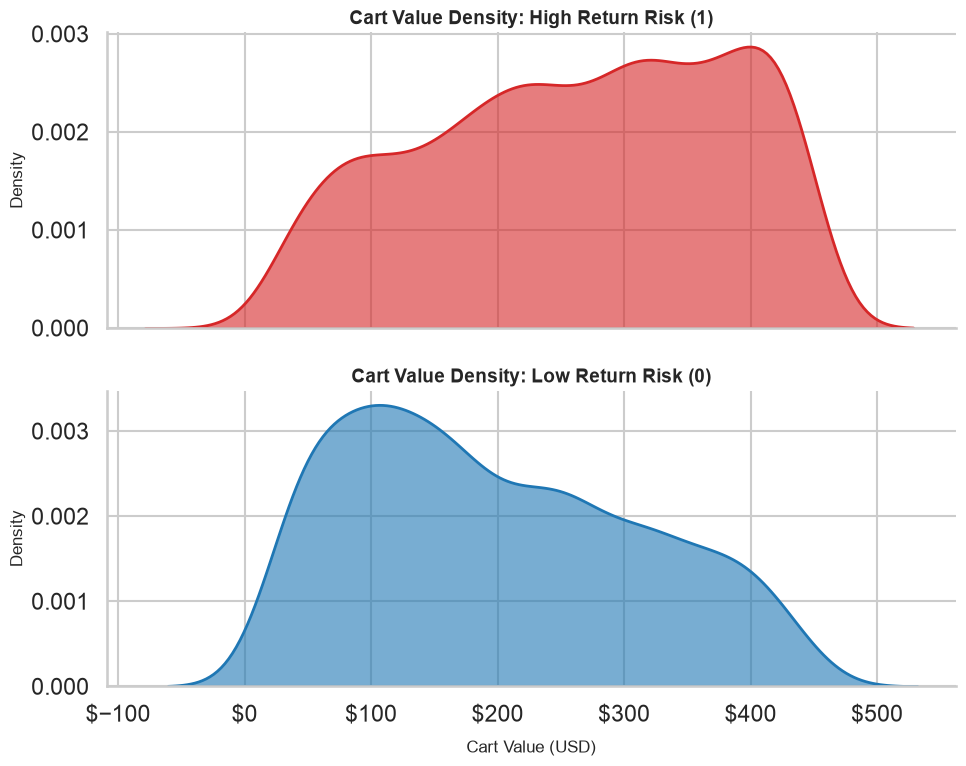

In [21]:
sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10, 8), sharex=True)

# Top Plot: Risk = 1
sns.kdeplot(
    data=df[df["return_risk_label"] == 1],
    x="cart_value_usd",
    fill=True,
    alpha=0.6,
    color="#d62728", # Red implies risk/action
    linewidth=2,
    ax=axes[0]
)
axes[0].set_title("Cart Value Density: High Return Risk (1)", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Density", fontsize=12, fontweight="medium")

# Bottom Plot: Risk = 0
sns.kdeplot(
    data=df[df["return_risk_label"] == 0],
    x="cart_value_usd",
    fill=True,
    alpha=0.6,
    color="#1f77b4", # Blue implies normal/safe
    linewidth=2,
    ax=axes[1]
)
axes[1].set_title("Cart Value Density: Low Return Risk (0)", fontsize=14, fontweight="bold")
axes[1].set_ylabel("Density", fontsize=12, fontweight="medium")
axes[1].set_xlabel("Cart Value (USD)", fontsize=12, fontweight="medium", labelpad=10)

axes[1].xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))

sns.despine()
plt.tight_layout()
plt.show()

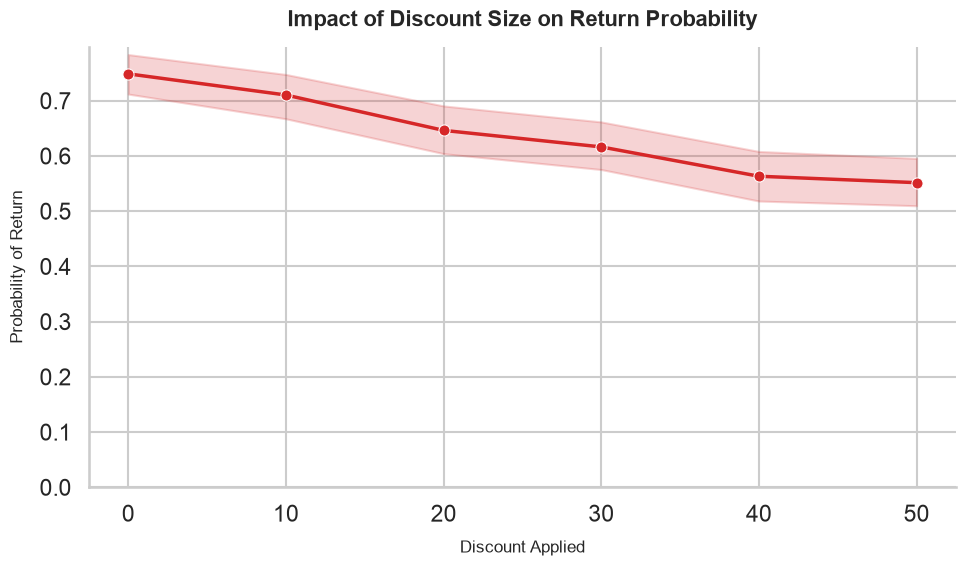

In [22]:
sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(10, 6))

ax2 = sns.lineplot(
    data=df,
    x="discount_pct_applied",
    y="return_risk_label",
    color="#d62728",
    linewidth=2.5,
    marker="o",
    markersize=8,
    errorbar=("ci", 95)
)

plt.title("Impact of Discount Size on Return Probability", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Discount Applied", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Probability of Return", fontsize=12, fontweight="medium", labelpad=10)

plt.ylim(0, None)

sns.despine()
plt.tight_layout()
plt.show()

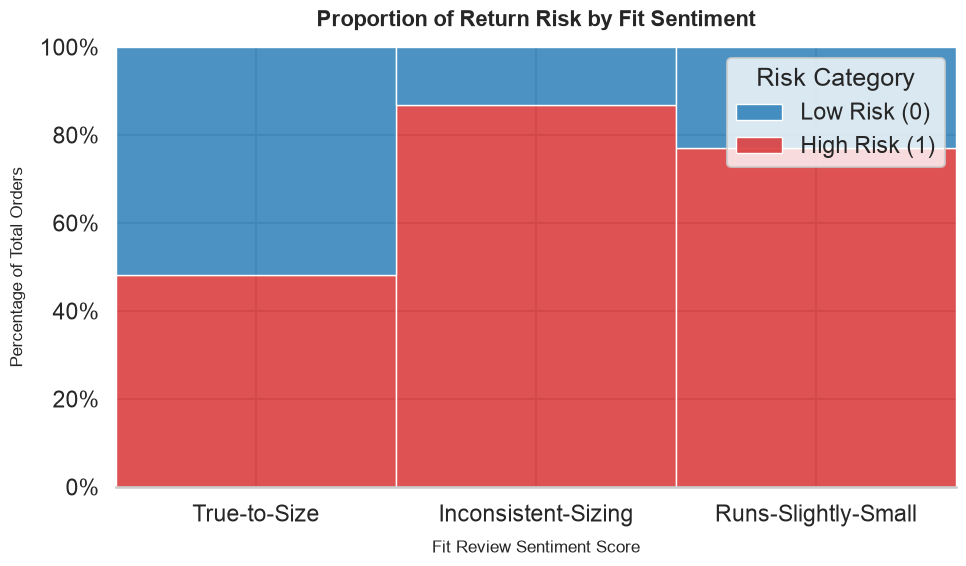

In [23]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(10, 6))

ax1 = sns.histplot(
    data=df,
    x="fit_review_sentiment",
    hue="return_risk_label",
    multiple="fill", 
    bins=15,
    palette=["#1f77b4", "#d62728"], # Blue = 0, Red = 1
    alpha=0.8,
    linewidth=1,
    edgecolor="white"
)

plt.title("Proportion of Return Risk by Fit Sentiment", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Fit Review Sentiment Score", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Percentage of Total Orders", fontsize=12, fontweight="medium", labelpad=10)

ax1.yaxis.set_major_formatter(PercentFormatter(1.0))

handles = ax1.get_legend().legend_handles
plt.legend(handles=handles, labels=["Low Risk (0)", "High Risk (1)"], title="Risk Category", loc="upper right", frameon=True)

sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

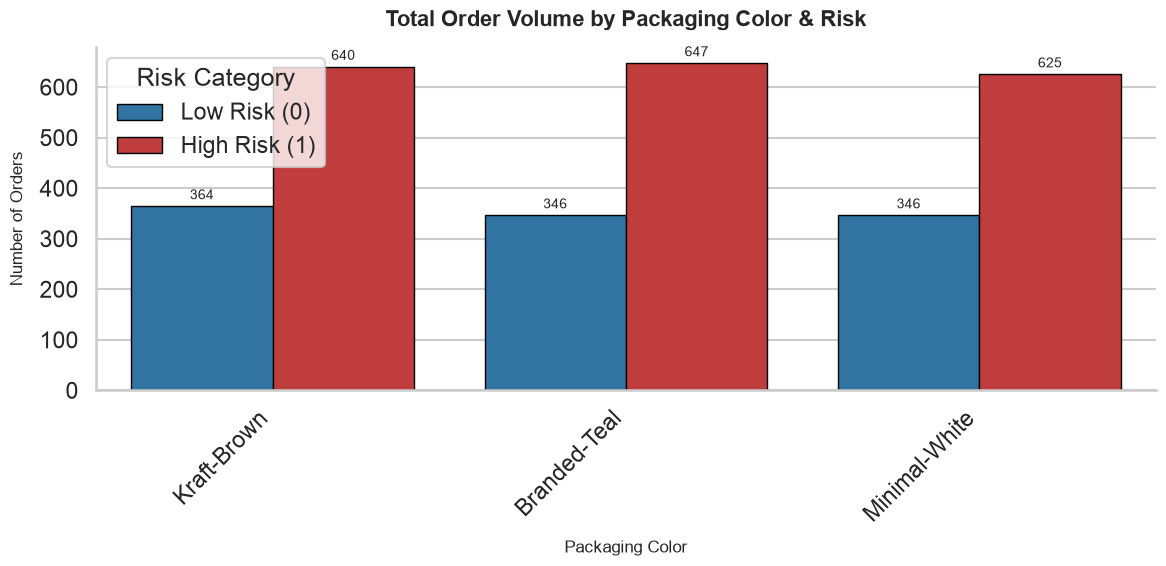

In [24]:
plt.figure(figsize=(12, 6))

# Sort by total volume (most popular packaging colors first)
volume_order = df['packaging_color'].value_counts().index

# Countplot shows raw volume split by the risk label
ax2 = sns.countplot(
    data=df,
    x="packaging_color",
    hue="return_risk_label",
    order=volume_order,
    palette=["#1f77b4", "#d62728"], # Blue = Safe, Red = Risk
    edgecolor="black",
    linewidth=1
)

plt.title("Total Order Volume by Packaging Color & Risk", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Packaging Color", fontsize=12, fontweight="medium", labelpad=10)
plt.ylabel("Number of Orders", fontsize=12, fontweight="medium", labelpad=10)

plt.xticks(rotation=45, ha="right")

# Clean up the legend
plt.legend(title="Risk Category", labels=["Low Risk (0)", "High Risk (1)"], frameon=True)

# Add data labels on top of the bars for exact counts
for container in ax2.containers:
    ax2.bar_label(container, fmt='%d', padding=3, fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

/var/folders/41/49dnj5213l1f6btjl3b5rdlh0000gn/T/ipykernel_4238/3891159435.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


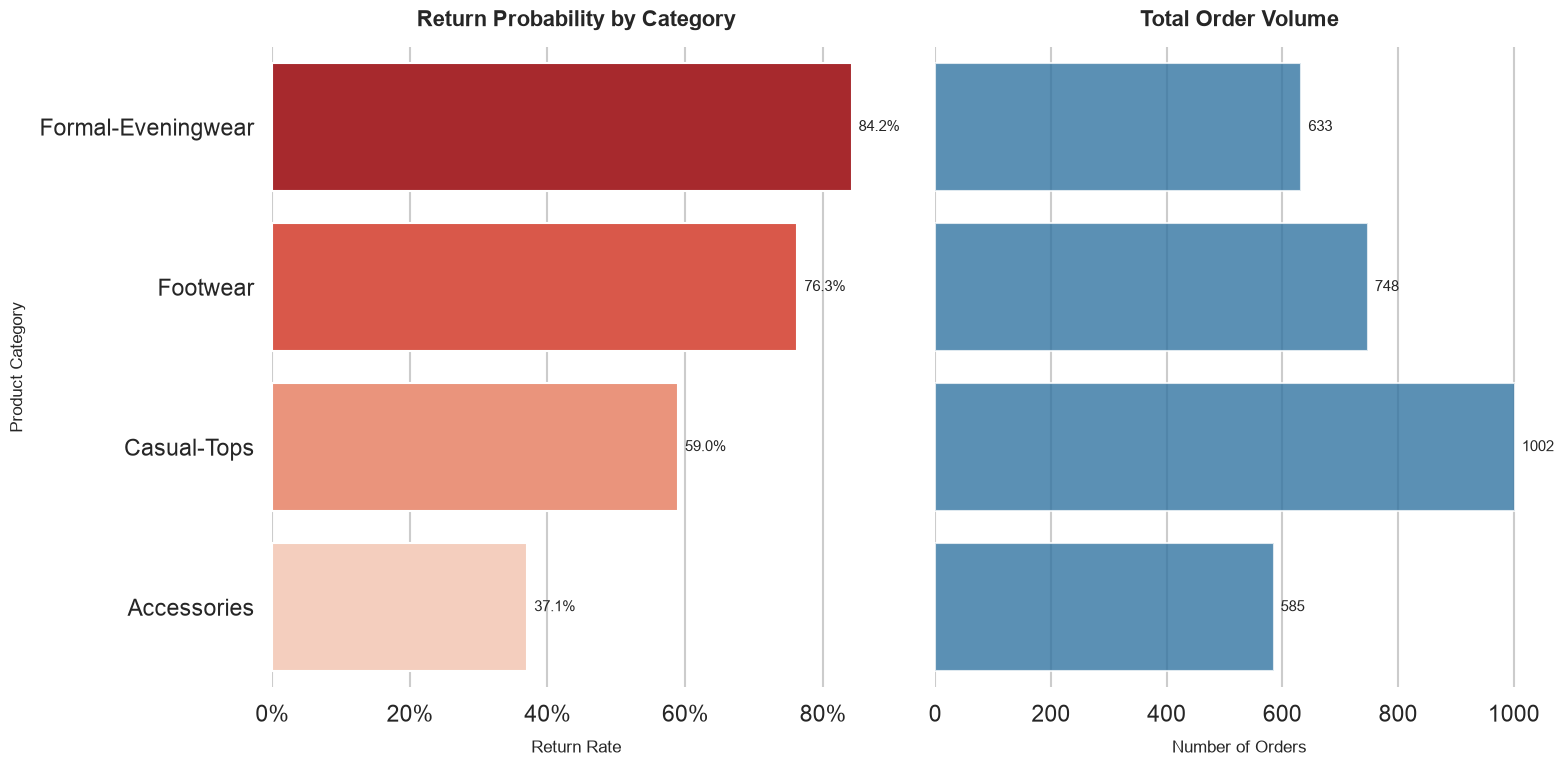

In [27]:
sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 8), sharey=True)

category_order = df.groupby('product_category')['return_risk_label'].mean().sort_values(ascending=False).index

sns.barplot(
    data=df,
    y="product_category",
    x="return_risk_label",
    order=category_order,
    palette="Reds_r", 
    errorbar=None,    
    ax=axes[0]
)

axes[0].set_title("Return Probability by Category", fontsize=16, fontweight="bold", pad=15)
axes[0].set_xlabel("Return Rate", fontsize=12, fontweight="medium", labelpad=10)
axes[0].set_ylabel("Product Category", fontsize=12, fontweight="medium", labelpad=10)

axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
for container in axes[0].containers:
    axes[0].bar_label(container, fmt=lambda x: f'{x*100:.1f}%', padding=5, fontsize=11)

sns.countplot(
    data=df,
    y="product_category",
    order=category_order,
    color="#1f77b4", 
    alpha=0.8,
    ax=axes[1]
)

axes[1].set_title("Total Order Volume", fontsize=16, fontweight="bold", pad=15)
axes[1].set_xlabel("Number of Orders", fontsize=12, fontweight="medium", labelpad=10)
axes[1].set_ylabel("") 

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%d', padding=5, fontsize=11)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

### Relationship Between Features and Target Variables

> 1. 